# Problems in Neural Network Training

In dieser Vorlesung betrachten wir Probleme die beim Training Neuronaler Netze auftreten können. Dies sind das Problem des Vanishing Gradients und das Problem des Overfittings.

## Vanishing Gradient Problem explained

In [1]:

# scatter plot of the circles dataset with points colored by class
from sklearn.datasets import make_circles
from numpy import where
from matplotlib import pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import TensorBoard
from tensorflow import keras





### Erzeugen von Daten eines nichtlinearen Klassifikationsproblems

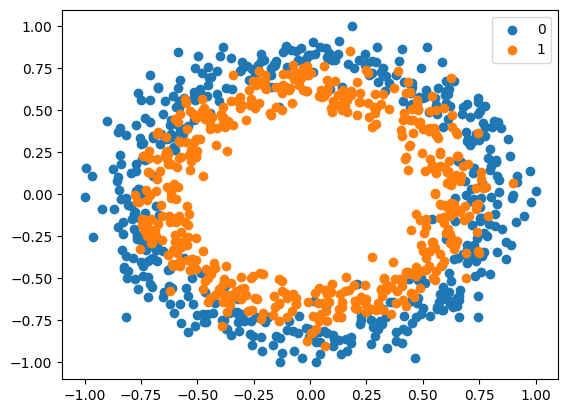

In [2]:
# generate circles
X, y = make_circles(n_samples=1000, noise=0.1, random_state=1)
scaler = MinMaxScaler(feature_range=(-1, 1))
#scaler =StandardScaler()
X = scaler.fit_transform(X)

# select indices of points with each class label
for i in range(2):
	samples_ix = where(y == i)
	plt.scatter(X[samples_ix, 0], X[samples_ix, 1], label=str(i))
plt.legend()



In [10]:
n_train = 500
trainX, testX = X[:n_train, :], X[n_train:, :]
trainy, testy = y[:n_train], y[n_train:]
# define model
model_small = Sequential()
model_small.add(Dense(5, input_dim=2,activation='tanh'))
model_small.add(Dense(1, activation='sigmoid'))
# compile model
opt = SGD(lr=0.01, momentum=0.9)
model_small.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
# fit model



history = model_small.fit(trainX, trainy, validation_data=(testX, testy), epochs=500, verbose=0)



Train: 0.818, Test: 0.832


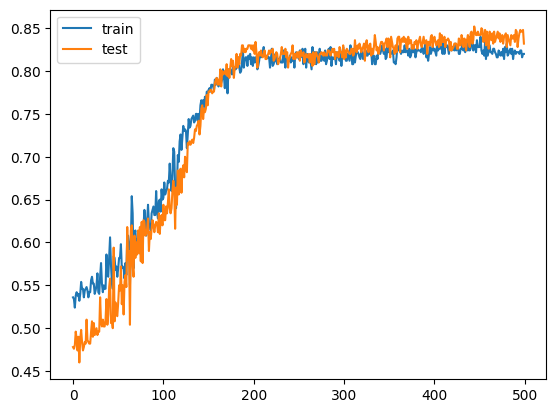

In [11]:
# evaluate the model
_, train_acc = model_small.evaluate(trainX, trainy, verbose=0)
_, test_acc = model_small.evaluate(testX, testy, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# plot training history
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()

In [27]:
model_5s = Sequential()
model_5s.add(Dense(5, input_dim=2,activation='sigmoid'))
model_5s.add(Dense(5, activation='sigmoid'))
model_5s.add(Dense(5, activation='sigmoid'))
model_5s.add(Dense(5, activation='sigmoid'))
model_5s.add(Dense(5, activation='sigmoid'))
model_5s.add(Dense(1, activation='sigmoid'))
model_5s.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
# fit model




history = model_5s.fit(trainX, trainy, validation_data=(testX, testy), epochs=500, verbose=0)

Train: 0.496, Test: 0.504


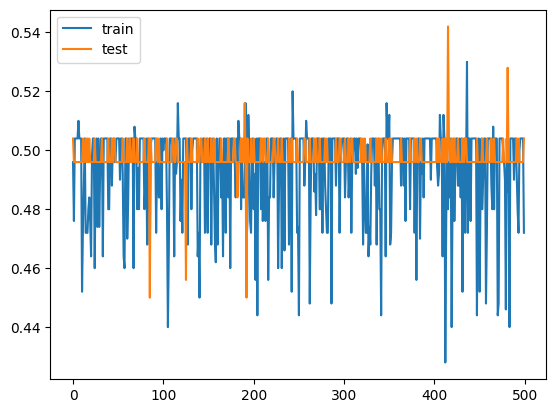

In [28]:
# evaluate the model
_, train_acc = model_5s.evaluate(trainX, trainy, verbose=0)
_, test_acc = model_5s.evaluate(testX, testy, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# plot training history
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()

## RELU

In [8]:
def relu(X):
    return np.maximum(0,X)

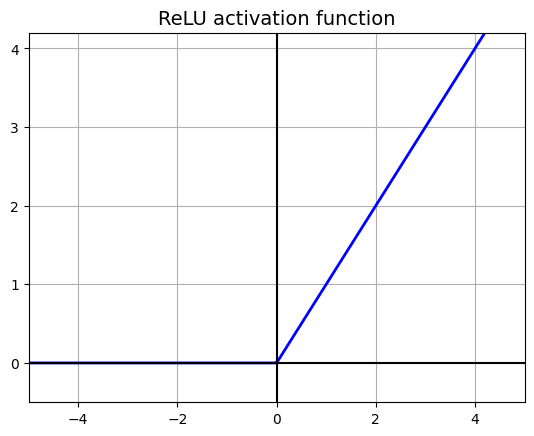

In [10]:
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-5, 5, 200)

plt.plot(z, relu(z), "b-", linewidth=2)
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-0.5, 4.2], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.title("ReLU activation function", fontsize=14)
plt.axis([-5, 5, -0.5, 4.2])

plt.show()

In [ ]:
model_5relu = Sequential()
model_5relu.add(Dense(5, input_dim=2, activation='relu'))
model_5relu.add(Dense(5, activation='relu'))
model_5relu.add(Dense(5, activation='relu'))
model_5relu.add(Dense(5, activation='relu'))
model_5relu.add(Dense(5, activation='relu'))
model_5relu.add(Dense(5, activation='relu'))
model_5relu.add(Dense(1, activation='sigmoid'))

## Leaky RELU

In [13]:
def leaky_relu(z, alpha=0.01):
    return np.maximum(alpha*z, z)

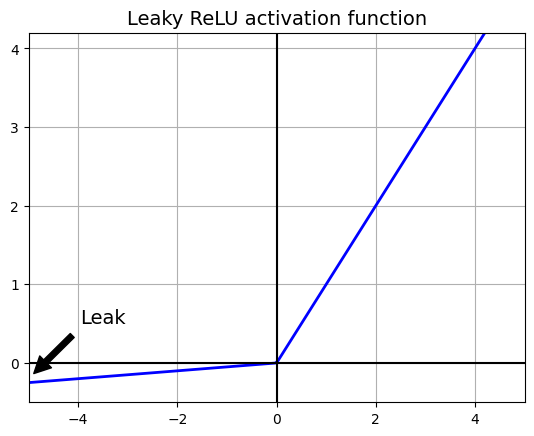

In [14]:
plt.plot(z, leaky_relu(z, 0.05), "b-", linewidth=2)
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-0.5, 4.2], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.2), arrowprops=props, fontsize=14, ha="center")
plt.title("Leaky ReLU activation function", fontsize=14)
plt.axis([-5, 5, -0.5, 4.2])

plt.show()

## ELU

In [16]:
def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

(-5.0, 5.0, -2.2, 3.2)

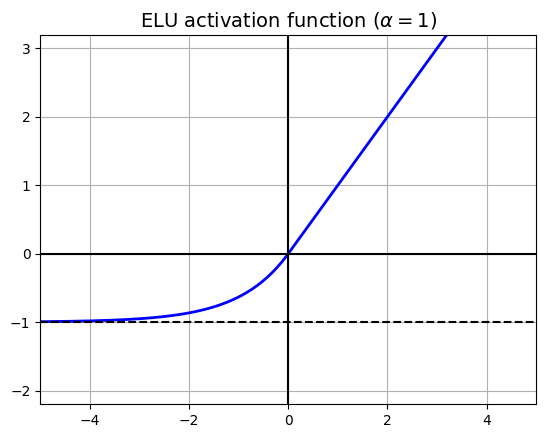

In [17]:
plt.plot(z, elu(z), "b-", linewidth=2)
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k--')
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.title(r"ELU activation function ($\alpha=1$)", fontsize=14)
plt.axis([-5, 5, -2.2, 3.2])

In [30]:
model_5relu.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])



# fit model
history = model_5relu.fit(trainX, trainy, validation_data=(testX, testy), epochs=500, verbose=0)

Train: 0.840, Test: 0.834


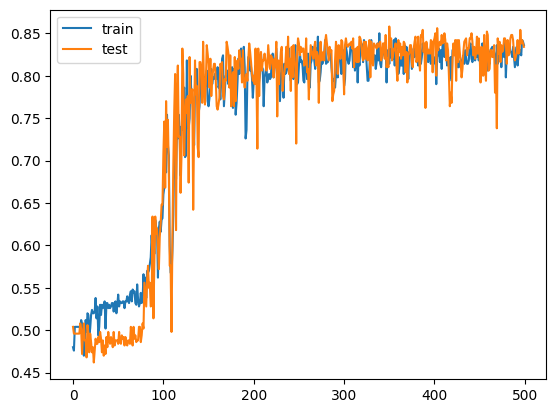

In [ ]:
# evaluate the model
_, train_acc = model_5relu.evaluate(trainX, trainy, verbose=0)
_, test_acc = model_5relu.evaluate(testX, testy, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# plot training history
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()